# PINNs for Mechanical Engineers — Tutorial 6: Backward Facing Step
### Flow that lets go of the wall: separation, reattachment, and a bubble the network has to find

*📺 Video on YouTube | 🐍 Python · PyTorch | Advanced*

*Notebook repository: [github.com/rraj-io/PINN_for_Mechanical_Engineer](https://github.com/rraj-io/PINN_for_Mechanical_Engineer)*

---

## Series Roadmap

This series applies physics-informed neural networks to the problems mechanical engineers actually deal with — fluids, heat, solids, and the messy places where they couple. Tutorial 5 was a held breath: one clean equation. This one goes back to the deep end. A fluid flows over a sudden drop in the floor, **separates** from the wall, swirls in a recirculation bubble, and **reattaches** downstream — and the PINN has to discover that bubble on its own, from nothing but the equations.


| # | Tutorial | Focus | Status |
|---|----------|-------|--------|
| 1 | 2D Navier–Stokes — lid-driven cavity | coupled, nonlinear flow | ✅ Published |
| 2 | 2D Steady Heat Conduction | mixed Dirichlet/Neumann BCs | ✅ Published |
| 3 | Linear Elasticity — plate with a hole | vector fields, stress concentration | ✅ Published |
| 4 | Natural Convection — buoyant cavity | multiphysics coupling | ✅ Published |
| 5 | Euler–Bernoulli Beam | 4th-order derivatives | ✅ Published |
| **6** | **Backward-Facing Step** | **flow separation & reattachment** | **📍 You are here**  |
| 7 | Unsteady Vortex Shedding — cylinder wake | the hard one: unsteady + failure modes | Planned |

Every tutorial is standalone and validated against a reference solution — and this one comes full circle: the beam has an **exact analytical solution**, so for the first time since Tutorial 3 we can check the PINN against a closed form, to the last digit.

> **New to PINNs?** This series assumes you're comfortable with the fundamentals: autograd, collocation points, the residual loss, the Adam → L-BFGS recipe. If you're starting from zero — or want the build-it-from-scratch treatment in one place — the 100+ page ebook covers all of it, from your first autograd call through 1D ODEs, Poisson, and Burgers.
>
> 👉 **[Get *PINNs from Scratch* on Gumroad](https://rajrohit403.gumroad.com/l/pinn_tutorial)**

---



## 1 — What You Will Learn

By the end of this notebook you will have:

- Solved the **steady incompressible 2D Navier–Stokes equations** with a PINN on a **backward-facing step**
- Handled a mixed set of boundary conditions: a prescribed **parabolic inlet**, an **outflow** outlet, and **no-slip walls**
- Sampled an **L-shaped domain** with extra points near the re-entrant corner
- Trained a velocity–pressure network that predicts $(u,v,p)$ directly
- Used a simple laminar Reynolds-number continuation to help the network discover the recirculation bubble
- Measured the **reattachment length** $x_r$ from the sign change of the lower-wall shear
- Checked the result with residual RMS values, boundary errors, and mass-flow conservation

**Prerequisites:** the PINN fundamentals, and Tutorial 1 in particular — this is the same steady Navier–Stokes machinery (two momentum residuals, continuity, the pressure gauge) you built for the lid-driven cavity. What's new is the **geometry and the boundary conditions**: an open flow with an inlet and an outlet instead of a closed box, and a step that forces the flow to separate. If the Navier–Stokes fundamentals feel shaky, revisit Tutorial 1, or the [*PINNs from Scratch* ebook](https://rajrohit403.gumroad.com/l/pinn_tutorial) for the foundations.

---

## 2 — The problem and its reference

We solve the steady incompressible Navier–Stokes equations in non-dimensional form. The reference length is the **step height** $s$, the reference velocity is the mean inlet velocity $\bar U$, and pressure is scaled by $\rho\bar U^2$:

$$
\begin{aligned}
u u_x + v u_y &= -p_x + \frac{1}{Re_s}(u_{xx}+u_{yy}),\\
u v_x + v v_y &= -p_y + \frac{1}{Re_s}(v_{xx}+v_{yy}),\\
u_x + v_y &= 0.
\end{aligned}
$$

Here $Re_s=\bar U s/\nu$. We use $Re_s=100$ as the default target: comfortably laminar for this two-dimensional tutorial, but high enough to produce a visible recirculation region.

### The geometry

The expansion ratio is $ER=H/h=2$, with $h=s=1$ and $H=2$:

- **Inlet channel:** $x\in[-L_i,0]$, $y\in[1,2]$
- **Expanded channel:** $x\in[0,L_o]$, $y\in[0,2]$
- **Step face:** $x=0$, $y\in[0,1]$

The fluid domain is therefore L-shaped. The sharp corner at $(0,1)$ is where the boundary layer separates.

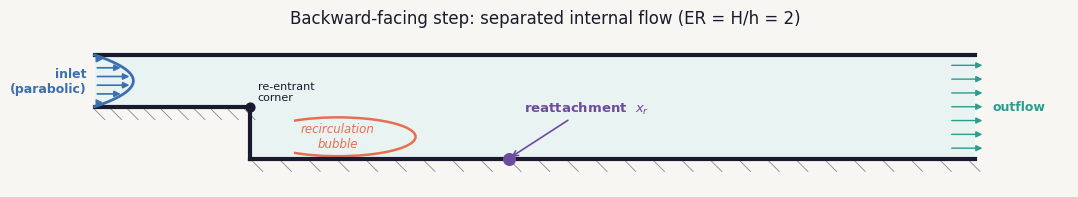

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch, Polygon, Arc

BG="#f7f6f2"; CORAL="#E76F51"; TEAL="#2A9D8F"; INK="#1A1A2E"; PUR="#6D4C9E"; BLUE="#3B6FB0"
Li=3.0; Lo=14.0; h=1.0; s=1.0; H=2.0
fig,ax=plt.subplots(figsize=(11,4.0)); fig.patch.set_facecolor(BG); ax.set_facecolor(BG)

# fluid domain: inlet rectangle + expanded rectangle
dom=Polygon([(-Li,s),(-Li,H),(Lo,H),(Lo,0),(0,0),(0,s)],closed=True,
            facecolor="#e9f3f1",edgecolor='none',zorder=0)
ax.add_patch(dom)

# solid boundaries
ax.plot([-Li,Lo],[H,H],color=INK,lw=3)
ax.plot([-Li,0],[s,s],color=INK,lw=3)
ax.plot([0,0],[0,s],color=INK,lw=3)
ax.plot([0,Lo],[0,0],color=INK,lw=3)
for xx in np.linspace(-Li,-0.1,10):
    ax.plot([xx,xx+0.2],[s-0.05,s-0.25],color=INK,lw=0.6,alpha=0.5)
for xx in np.linspace(0.05,Lo-0.1,26):
    ax.plot([xx,xx+0.2],[-0.05,-0.25],color=INK,lw=0.6,alpha=0.5)

# inlet parabola: mean velocity = 1
yy=np.linspace(s,H,40)
uu=6*(yy-s)*(H-yy)
ax.plot(-Li+0.5*uu,yy,color=BLUE,lw=2)
for yv in np.linspace(s+0.08,H-0.08,6):
    uv=6*(yv-s)*(H-yv)
    ax.add_patch(FancyArrowPatch((-Li,yv),(-Li+0.5*uv,yv),arrowstyle='-|>',
                                 mutation_scale=9,color=BLUE,lw=1.2))
ax.text(-Li-0.15,(s+H)/2,"inlet\n(parabolic)",color=BLUE,ha='right',va='center',fontsize=9,weight='bold')

# recirculation bubble and reattachment point
ax.add_patch(Arc((1.7,0.42),3.0,0.75,angle=0,theta1=200,theta2=520,color=CORAL,lw=1.8))
ax.text(1.7,0.42,"recirculation\nbubble",color=CORAL,ha='center',va='center',fontsize=8.5,style='italic')
xr=5.0
ax.scatter([xr],[0],s=70,color=PUR,zorder=6)
ax.annotate(r"reattachment  $x_r$",xy=(xr,0),xytext=(xr+0.3,0.9),color=PUR,fontsize=9.5,weight='bold',
            arrowprops=dict(arrowstyle='->',color=PUR,lw=1.2))

# outlet arrows
for yv in np.linspace(0.2,H-0.2,7):
    ax.add_patch(FancyArrowPatch((Lo-0.5,yv),(Lo+0.2,yv),arrowstyle='-|>',
                                 mutation_scale=9,color=TEAL,lw=1.0))
ax.text(Lo+0.35,H/2,"outflow",color=TEAL,ha='left',va='center',fontsize=9,weight='bold')

ax.scatter([0],[s],s=40,color=INK,zorder=6)
ax.text(0.15,s+0.12,"re-entrant\ncorner",color=INK,fontsize=8)
ax.set_xlim(-Li-1.4,Lo+1.8); ax.set_ylim(-0.55,H+0.45); ax.set_aspect('equal'); ax.axis('off')
ax.set_title("Backward-facing step: separated internal flow (ER = H/h = 2)",color=INK,fontsize=12)
plt.tight_layout(); plt.show()


### Boundary conditions

| Boundary | Location | Condition |
|----------|----------|-----------|
| Inlet | $x=-L_i$, $y\in[1,2]$ | $u=6(y-1)(2-y)$, $v=0$ |
| Outlet | $x=L_o$ | $u_x=0$, $v_x=0$, $p=0$ |
| Walls | top, inlet floor, step face, expanded floor | $u=v=0$ |

The inlet profile has unit mean velocity and a maximum of $1.5$. The pressure condition at the outlet fixes the otherwise arbitrary pressure gauge. The velocity-gradient conditions allow the developed flow to leave without prescribing its exact outlet profile.

### What counts as validation?

There is no analytical $(u,v,p)$ solution. We therefore validate in layers:

1. the PDE residuals are small at independent points;
2. the boundary conditions are satisfied;
3. the mass flow remains close to the inlet value $Q=1$;
4. a region with $u<0$ appears behind the step;
5. the lower-wall shear changes sign at a physically reasonable reattachment location.

---

## 3 — Imports and Setup

The style stays deliberately close to the earlier tutorials: imports, one seed, one device selection, and all of the main constants in one visible cell. On a CUDA machine the notebook automatically selects the full training settings; on CPU it selects a short code-check run.

In [2]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
import math, time

# reproducibility
torch.manual_seed(0)
np.random.seed(0)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")
if device.type == 'cuda':
    print(f"GPU: {torch.cuda.get_device_name(0)}")

# geometry and target Reynolds number
Li=3.0; Lo=14.0; h=1.0; s=1.0; H=2.0
RE_TARGET = 100.0

# automatic full GPU run; set FULL_TRAINING=False for a quick code check
FULL_TRAINING = device.type == 'cuda'
N_f = 5000 if FULL_TRAINING else 500                  # interior points
N_b = 300  if FULL_TRAINING else 50                   # points on each boundary segment
ADAM_ITERS_PER_STAGE = 2000 if FULL_TRAINING else 5
LBFGS_ITERS = 300 if FULL_TRAINING else 3
LOG_EVERY = 100 if FULL_TRAINING else 1
RUN_LBFGS = True

# viscous-to-target continuation remains entirely inside the laminar range
RE_STAGES = [20.0, 50.0, RE_TARGET]

print(f"Problem: steady 2D laminar backward-facing step | ER=2 | target Re_s={RE_TARGET:g}")
print(f"Training: N_f={N_f}, N_b={N_b}, Adam/stage={ADAM_ITERS_PER_STAGE}, L-BFGS={LBFGS_ITERS}")

Using device: cuda
GPU: Tesla T4
Problem: steady 2D laminar backward-facing step | ER=2 | target Re_s=100
Training: N_f=5000, N_b=300, Adam/stage=2000, L-BFGS=300


---

## 4 — The reference quantities

Unlike the beam tutorial, there is no exact field to code first. We can still code the quantities that **are known exactly** before training:

- the inlet profile $u_{in}=6(y-1)(2-y)$;
- its unit mass flow $Q_{in}=\int_1^2u_{in}\,dy=1$;
- the fluid-domain mask;
- the approximate laminar reattachment scale used only as a comparison target, not as training data.

The PINN never sees a prescribed recirculation bubble or reattachment point.

In [3]:
def inlet_velocity(y):
    "Parabolic inlet profile with mean velocity equal to one."
    return 6.0*(y-s)*(H-y)

def inside_fluid(x, y):
    "Boolean mask for the L-shaped fluid domain."
    return ((x >= -Li) & (x <= 0) & (y >= s) & (y <= H)) | \
           ((x >= 0) & (x <= Lo) & (y >= 0) & (y <= H))

# exact inlet checks
y_ref = torch.linspace(s, H, 501, device=device).reshape(-1,1)
u_ref = inlet_velocity(y_ref)
Q_in = torch.trapz(u_ref[:,0], y_ref[:,0]).item()
print(f"inlet wall values: u(1)={u_ref[0].item():.4f}, u(2)={u_ref[-1].item():.4f}  (want 0, 0)")
print(f"inlet maximum:     {u_ref.max().item():.4f}  (want 1.5)")
print(f"inlet mass flow:   {Q_in:.6f}  (want 1.0)")

# approximate experimental comparison scale near Re_s=100; not used in the loss
XR_REFERENCE = 5.0
print(f"comparison scale near Re_s=100: x_r/s is of order {XR_REFERENCE:.1f}")

inlet wall values: u(1)=0.0000, u(2)=0.0000  (want 0, 0)
inlet maximum:     1.5000  (want 1.5)
inlet mass flow:   0.999996  (want 1.0)
comparison scale near Re_s=100: x_r/s is of order 5.0


---

## 5 — Collocation and boundary points

The L-shaped domain is sampled as two rectangles, with extra points behind the step:

- **Interior points** enforce the two momentum equations and continuity.
- **Inlet points** enforce the known parabolic profile.
- **Outlet points** enforce zero streamwise velocity gradients and $p=0$.
- **Wall points** enforce no slip on all four solid-wall segments.

The corner-focused points do not add new physics; they simply ask the network to resolve the region where the solution changes most rapidly.

In [4]:
gen = torch.Generator().manual_seed(42)

def rand_between(a, b, n):
    return (a + (b-a)*torch.rand(n,1,generator=gen)).to(device)

def sample_interior(n):
    "Interior points with deliberate extra resolution behind the step."
    n_pre = int(0.25*n)
    n_post = int(0.50*n)
    n_corner = n - n_pre - n_post

    pre = torch.cat([rand_between(-Li,0,n_pre), rand_between(s,H,n_pre)],dim=1)
    post = torch.cat([rand_between(0,Lo,n_post), rand_between(0,H,n_post)],dim=1)
    corner = torch.cat([rand_between(0,min(4.0,Lo),n_corner), rand_between(0,H,n_corner)],dim=1)
    return torch.cat([pre,post,corner],dim=0)

# interior
xy_f = sample_interior(N_f).requires_grad_(True)

# inlet and outlet
xy_in = torch.cat([-Li*torch.ones(N_b,1,device=device), rand_between(s,H,N_b)],dim=1)
xy_out = torch.cat([Lo*torch.ones(N_b,1,device=device), rand_between(0,H,N_b)],dim=1).requires_grad_(True)

# four no-slip wall segments
top = torch.cat([rand_between(-Li,Lo,N_b), H*torch.ones(N_b,1,device=device)],dim=1)
pre_floor = torch.cat([rand_between(-Li,0,N_b), s*torch.ones(N_b,1,device=device)],dim=1)
step_face = torch.cat([torch.zeros(N_b,1,device=device), rand_between(0,s,N_b)],dim=1)
post_floor = torch.cat([rand_between(0,Lo,N_b), torch.zeros(N_b,1,device=device)],dim=1)
xy_wall = torch.cat([top,pre_floor,step_face,post_floor],dim=0)

print(f"interior collocation points: {xy_f.shape[0]}")
print(f"inlet points: {xy_in.shape[0]} | outlet points: {xy_out.shape[0]}")
print(f"wall points: {xy_wall.shape[0]} ({N_b} on each wall segment)")

interior collocation points: 5000
inlet points: 300 | outlet points: 300
wall points: 1200 (300 on each wall segment)


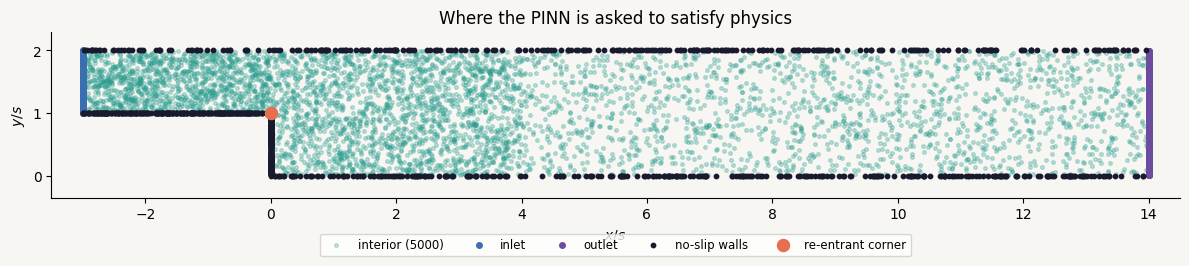

In [5]:
def np2(t):
    return t.detach().cpu().numpy()

CORAL="#E76F51"; TEAL="#2A9D8F"; INK="#1A1A2E"; PUR="#6D4C9E"; BLUE="#3B6FB0"; BG="#f7f6f2"
fig,ax=plt.subplots(figsize=(12,4.2)); fig.patch.set_facecolor(BG); ax.set_facecolor(BG)

f=np2(xy_f); bi=np2(xy_in); bo=np2(xy_out); bw=np2(xy_wall)
ax.scatter(f[:,0],f[:,1],s=7,alpha=0.28,color=TEAL,label=f"interior ({len(f)})")
ax.scatter(bi[:,0],bi[:,1],s=16,color=BLUE,label="inlet")
ax.scatter(bo[:,0],bo[:,1],s=16,color=PUR,label="outlet")
ax.scatter(bw[:,0],bw[:,1],s=10,color=INK,label="no-slip walls")
ax.scatter([0],[s],s=75,color=CORAL,zorder=6,label="re-entrant corner")

ax.set_xlim(-Li-0.5,Lo+0.5); ax.set_ylim(-0.35,H+0.3); ax.set_aspect('equal')
ax.set_xlabel('$x/s$'); ax.set_ylabel('$y/s$')
ax.set_title("Where the PINN is asked to satisfy physics")
ax.legend(loc='upper center',bbox_to_anchor=(0.5,-0.18),ncol=5,fontsize=8.5)
for q in ['top','right']: ax.spines[q].set_visible(False)
plt.tight_layout(); plt.show()

---

## 6 — The network 

Two inputs $(x,y)$, three outputs $(u,v,p)$. The architecture follows the same compact `nn.Sequential` style as the earlier tutorials. Coordinates are normalized inside the network because the streamwise domain is much longer than the channel height. We keep `tanh`: the momentum residuals require smooth second derivatives.

In [6]:
class PINN(nn.Module):
    "Input (x,y) -> outputs (u,v,p)."
    def __init__(self, n_hidden=64, n_layers=5):
        super().__init__()
        layers = [nn.Linear(2,n_hidden),nn.Tanh()]
        for _ in range(n_layers-1):
            layers += [nn.Linear(n_hidden,n_hidden),nn.Tanh()]
        layers += [nn.Linear(n_hidden,3)]
        self.net = nn.Sequential(*layers)
        self.register_buffer('lb',torch.tensor([-Li,0.0]))
        self.register_buffer('ub',torch.tensor([ Lo,H]))
        for m in self.net:
            if isinstance(m,nn.Linear):
                nn.init.xavier_normal_(m.weight)
                nn.init.zeros_(m.bias)
    def forward(self,xy):
        z = 2.0*(xy-self.lb)/(self.ub-self.lb)-1.0
        return self.net(z)

model = PINN().to(device)
n_params = sum(p.numel() for p in model.parameters())
print(model)
print(f"Trainable parameters: {n_params}")

PINN(
  (net): Sequential(
    (0): Linear(in_features=2, out_features=64, bias=True)
    (1): Tanh()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): Tanh()
    (4): Linear(in_features=64, out_features=64, bias=True)
    (5): Tanh()
    (6): Linear(in_features=64, out_features=64, bias=True)
    (7): Tanh()
    (8): Linear(in_features=64, out_features=64, bias=True)
    (9): Tanh()
    (10): Linear(in_features=64, out_features=3, bias=True)
  )
)
Trainable parameters: 17027


---

## 7 — The predicted fields and automatic differentiation

The network output is split into the three physical fields. Unlike the beam's fixed-end ansatz, the backward-facing-step boundary conditions are kept **soft** so that the code remains transparent: every inlet, wall, and outlet term appears explicitly in the loss.

One helper, `grad`, provides every first and second derivative used later.

In [7]:
def fields(xy):
    "Network fields u(x,y), v(x,y), p(x,y)."
    out = model(xy)
    return out[:,0:1],out[:,1:2],out[:,2:3]

def grad(o,i):
    return torch.autograd.grad(o,i,torch.ones_like(o),create_graph=True,retain_graph=True)[0]

# verify shapes before training
u0,v0,p0 = fields(xy_f[:8])
print(f"u shape: {tuple(u0.shape)} | v shape: {tuple(v0.shape)} | p shape: {tuple(p0.shape)}")
print(f"untrained mean values: u={u0.mean().item():+.3e}, v={v0.mean().item():+.3e}, p={p0.mean().item():+.3e}")

u shape: (8, 1) | v shape: (8, 1) | p shape: (8, 1)
untrained mean values: u=-1.946e-01, v=+1.683e-01, p=+3.798e-01


---

## 8 — The residual: momentum plus continuity

Automatic differentiation supplies the velocity gradients, pressure gradients, and velocity Laplacians. At every interior point we form three residuals:

$$
\begin{aligned}
r_x &= u u_x+v u_y+p_x-\frac{1}{Re}(u_{xx}+u_{yy}),\\
r_y &= u v_x+v v_y+p_y-\frac{1}{Re}(v_{xx}+v_{yy}),\\
r_c &= u_x+v_y.
\end{aligned}
$$

A perfect steady incompressible solution makes all three zero.

In [8]:
def residuals(xy,Re):
    "x-momentum, y-momentum, and continuity residuals."
    u,v,p = fields(xy)

    gu = grad(u,xy); gv = grad(v,xy); gp = grad(p,xy)
    u_x,u_y = gu[:,0:1],gu[:,1:2]
    v_x,v_y = gv[:,0:1],gv[:,1:2]
    p_x,p_y = gp[:,0:1],gp[:,1:2]

    u_xx = grad(u_x,xy)[:,0:1]; u_yy = grad(u_y,xy)[:,1:2]
    v_xx = grad(v_x,xy)[:,0:1]; v_yy = grad(v_y,xy)[:,1:2]

    r_x = u*u_x + v*u_y + p_x - (u_xx+u_yy)/Re
    r_y = u*v_x + v*v_y + p_y - (v_xx+v_yy)/Re
    r_c = u_x + v_y
    return r_x,r_y,r_c

# demo on the untrained network
r_x,r_y,r_c = residuals(xy_f[:64],RE_TARGET)
print(f"residual shapes: {tuple(r_x.shape)}, {tuple(r_y.shape)}, {tuple(r_c.shape)}")
print(f"untrained RMS: rx={r_x.square().mean().sqrt().item():.3e}, "
      f"ry={r_y.square().mean().sqrt().item():.3e}, rc={r_c.square().mean().sqrt().item():.3e}")

residual shapes: (64, 1), (64, 1), (64, 1)
untrained RMS: rx=4.991e-02, ry=1.485e-01, rc=3.364e-02


---

## 9 — The loss

The total loss keeps the physics and each boundary family visible:

$$
\mathcal L=\mathcal L_{PDE}
+\lambda_i\mathcal L_{inlet}
+\lambda_w\mathcal L_{walls}
+\lambda_o\mathcal L_{outlet}.
$$

The outlet term contains both the pressure gauge and the zero streamwise velocity gradients. The weights below are starting values, not universal constants; the component history will show whether one family is being ignored.

In [9]:
W_INLET = 10.0
W_WALL = 10.0
W_OUTLET = 1.0

def mse(z): return (z**2).mean()

def compute_losses(Re):
    # interior Navier-Stokes equations
    r_x,r_y,r_c = residuals(xy_f,Re)
    loss_pde = mse(r_x)+mse(r_y)+mse(r_c)

    # inlet profile
    u_i,v_i,_ = fields(xy_in)
    u_target = inlet_velocity(xy_in[:,1:2])
    loss_in = mse(u_i-u_target)+mse(v_i)

    # no-slip walls
    u_w,v_w,_ = fields(xy_wall)
    loss_wall = mse(u_w)+mse(v_w)

    # outlet: zero velocity gradients and pressure gauge
    u_o,v_o,p_o = fields(xy_out)
    u_x = grad(u_o,xy_out)[:,0:1]
    v_x = grad(v_o,xy_out)[:,0:1]
    loss_out = mse(u_x)+mse(v_x)+mse(p_o)
    return loss_pde,loss_in,loss_wall,loss_out

def total_loss(Re):
    lp,li,lw,lo = compute_losses(Re)
    return lp + W_INLET*li + W_WALL*lw + W_OUTLET*lo

# demo on the untrained network
lp,li,lw,lo = compute_losses(RE_STAGES[0])
print(f"untrained: pde={lp.item():.3e} inlet={li.item():.3e} wall={lw.item():.3e} outlet={lo.item():.3e}")

untrained: pde=3.663e-02 inlet=1.736e+00 wall=3.676e-02 outlet=1.457e-01


---

## 10 — Two-phase training: Adam → L-BFGS

The recipe is the same as the previous tutorials. Adam first finds a useful basin; L-BFGS then polishes the final full-batch residual.

The only addition is a short **laminar Reynolds continuation**. The same model is trained at $Re_s=20$, then $50$, then the target $100$. This does not introduce turbulence modelling or extra equations. It simply lets the network learn the viscous solution before asking it to represent stronger separation.

In [10]:
@torch.no_grad()
def mass_flow(x0,n=201):
    y0 = s if x0 < 0 else 0.0
    y = torch.linspace(y0,H,n,device=device).reshape(-1,1)
    x = x0*torch.ones_like(y)
    u,_,_ = fields(torch.cat([x,y],dim=1))
    return torch.trapz(u[:,0],y[:,0]).item()

@torch.no_grad()
def minimum_reverse_velocity():
    x = torch.linspace(0.1,6.0,100,device=device)
    y = torch.linspace(0.02,0.7,40,device=device)
    X,Y = torch.meshgrid(x,y,indexing='ij')
    u,_,_ = fields(torch.stack([X.flatten(),Y.flatten()],dim=1))
    return u.min().item()

history = {"epoch":[],"total":[],"pde":[],"inlet":[],"wall":[],"outlet":[],
           "reverse":[],"mass":[],"phase":[],"Re":[]}

def record(epoch,phase,Re):
    lp,li,lw,lo = compute_losses(Re)
    history["epoch"].append(epoch)
    history["total"].append((lp+W_INLET*li+W_WALL*lw+W_OUTLET*lo).item())
    history["pde"].append(lp.item()); history["inlet"].append(li.item())
    history["wall"].append(lw.item()); history["outlet"].append(lo.item())
    history["reverse"].append(minimum_reverse_velocity())
    history["mass"].append(abs(mass_flow(0.8*Lo)-1.0))
    history["phase"].append(phase); history["Re"].append(Re)

# --- Stage 1: Adam, with laminar Re continuation ---
opt = torch.optim.Adam(model.parameters(),lr=1e-3)
step = 0
start = time.time()
for Re in RE_STAGES:
    print(f"\nAdam stage: Re_s={Re:g}")
    for local in range(ADAM_ITERS_PER_STAGE+1):
        opt.zero_grad(); total_loss(Re).backward(); opt.step()
        if local % LOG_EVERY == 0:
            record(step,"Adam",Re)
            print(f"[Adam] step={step:5d} Re={Re:5.1f} loss={history['total'][-1]:.3e} "
                  f"umin={history['reverse'][-1]:+.3e} mass_err={history['mass'][-1]:.2e}")
        step += 1

# --- Stage 2: L-BFGS at the target Reynolds number ---
HANDOFF = step
if RUN_LBFGS:
    opt = torch.optim.LBFGS(model.parameters(),lr=1.0,max_iter=LBFGS_ITERS,history_size=50,
                            line_search_fn='strong_wolfe',tolerance_grad=1e-10,tolerance_change=1e-12)
    calls = [0]
    def closure():
        opt.zero_grad(); L=total_loss(RE_TARGET); L.backward(); calls[0]+=1
        if calls[0] % max(1,LBFGS_ITERS//10) == 0:
            record(HANDOFF+calls[0],"LBFGS",RE_TARGET)
        return L
    opt.step(closure)

record(HANDOFF+LBFGS_ITERS+1,"LBFGS",RE_TARGET)
print(f"\nTraining complete in {(time.time()-start)/60:.2f} min")
print(f"final minimum u behind step = {minimum_reverse_velocity():+.4f}")
print(f"final outlet mass-flow error = {abs(mass_flow(0.8*Lo)-1.0):.3e}")

torch.save({"model_state":model.state_dict(),"history":history,"Re":RE_TARGET},
           "bfs_pinn_tutorial_style.pt")
print("saved: bfs_pinn_tutorial_style.pt")


Adam stage: Re_s=20
[Adam] step=    0 Re= 20.0 loss=9.855e+00 umin=+1.413e-02 mass_err=1.03e+00
[Adam] step=  100 Re= 20.0 loss=6.587e-01 umin=-5.210e-01 mass_err=1.44e+00
[Adam] step=  200 Re= 20.0 loss=3.362e-01 umin=-4.374e-01 mass_err=1.67e+00
[Adam] step=  300 Re= 20.0 loss=2.817e-01 umin=-4.182e-01 mass_err=1.82e+00
[Adam] step=  400 Re= 20.0 loss=2.475e-01 umin=-3.524e-01 mass_err=1.89e+00
[Adam] step=  500 Re= 20.0 loss=2.182e-01 umin=-2.631e-01 mass_err=1.87e+00
[Adam] step=  600 Re= 20.0 loss=1.574e-01 umin=-1.052e-01 mass_err=1.58e+00
[Adam] step=  700 Re= 20.0 loss=8.238e-02 umin=-2.474e-02 mass_err=1.07e+00
[Adam] step=  800 Re= 20.0 loss=5.254e-02 umin=-1.761e-02 mass_err=9.49e-01
[Adam] step=  900 Re= 20.0 loss=3.540e-02 umin=-1.598e-02 mass_err=9.61e-01
[Adam] step= 1000 Re= 20.0 loss=2.573e-02 umin=-1.417e-02 mass_err=9.75e-01
[Adam] step= 1100 Re= 20.0 loss=3.418e-02 umin=-9.756e-03 mass_err=9.86e-01
[Adam] step= 1200 Re= 20.0 loss=3.966e-02 umin=-2.122e-02 mass_err=

---

## 11 — The Loss History, Both Phases

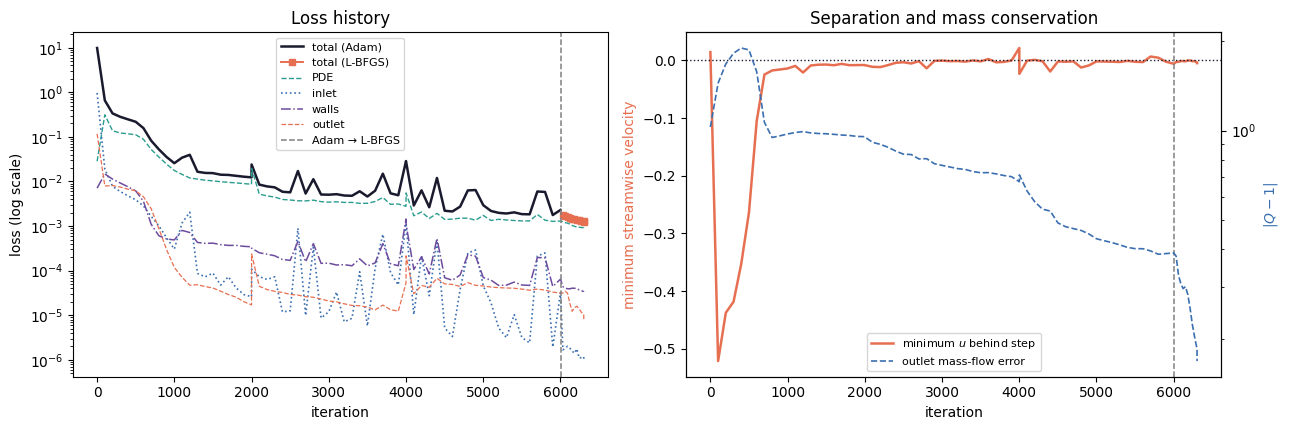

In [11]:
epoch=np.array(history["epoch"])
tot=np.array(history["total"]); pde=np.array(history["pde"])
inlet=np.array(history["inlet"]); wall=np.array(history["wall"]); outlet=np.array(history["outlet"])
reverse=np.array(history["reverse"]); mass=np.array(history["mass"])
ph=np.array(history["phase"]); am=ph=="Adam"; lm=ph=="LBFGS"
INK="#1A1A2E"; CORAL="#E76F51"; TEAL="#2A9D8F"; PUR="#6D4C9E"; BLUE="#3B6FB0"

fig,ax=plt.subplots(1,2,figsize=(13,4.4))
# loss components
ax[0].semilogy(epoch[am],tot[am],'-',color=INK,lw=1.8,label='total (Adam)')
ax[0].semilogy(epoch[lm],tot[lm],'s-',color=CORAL,ms=4,lw=1.4,label='total (L-BFGS)')
ax[0].semilogy(epoch,pde,'--',color=TEAL,lw=1.0,label='PDE')
ax[0].semilogy(epoch,np.maximum(inlet,1e-14),':',color=BLUE,lw=1.2,label='inlet')
ax[0].semilogy(epoch,np.maximum(wall,1e-14),'-.',color=PUR,lw=1.1,label='walls')
ax[0].semilogy(epoch,np.maximum(outlet,1e-14),'--',color=CORAL,lw=0.9,label='outlet')
ax[0].axvline(HANDOFF,color='gray',ls='--',lw=1.1,label='Adam → L-BFGS')
ax[0].set_xlabel('iteration'); ax[0].set_ylabel('loss (log scale)')
ax[0].set_title('Loss history'); ax[0].legend(fontsize=8)

# physical indicators
ax2=ax[1]; ax3=ax2.twinx()
ax2.plot(epoch,reverse,'-',color=CORAL,lw=1.8,label='minimum $u$ behind step')
ax2.axhline(0,color=INK,ls=':',lw=1)
ax3.semilogy(epoch,np.maximum(mass,1e-12),'--',color=BLUE,lw=1.2,label='outlet mass-flow error')
ax2.axvline(HANDOFF,color='gray',ls='--',lw=1.1)
ax2.set_xlabel('iteration'); ax2.set_ylabel('minimum streamwise velocity',color=CORAL)
ax3.set_ylabel('$|Q-1|$',color=BLUE); ax2.set_title('Separation and mass conservation')
h1,l1=ax2.get_legend_handles_labels(); h2,l2=ax3.get_legend_handles_labels()
ax2.legend(h1+h2,l1+l2,fontsize=8,loc='best')
plt.tight_layout(); plt.show()

---

## 12 — Results and validation

The field plots answer the first qualitative question: did the network discover a reversed-flow region behind the step? The numerical checks then ask stricter questions about mass conservation, boundary errors, independent PDE residuals, and the wall-shear reattachment location.

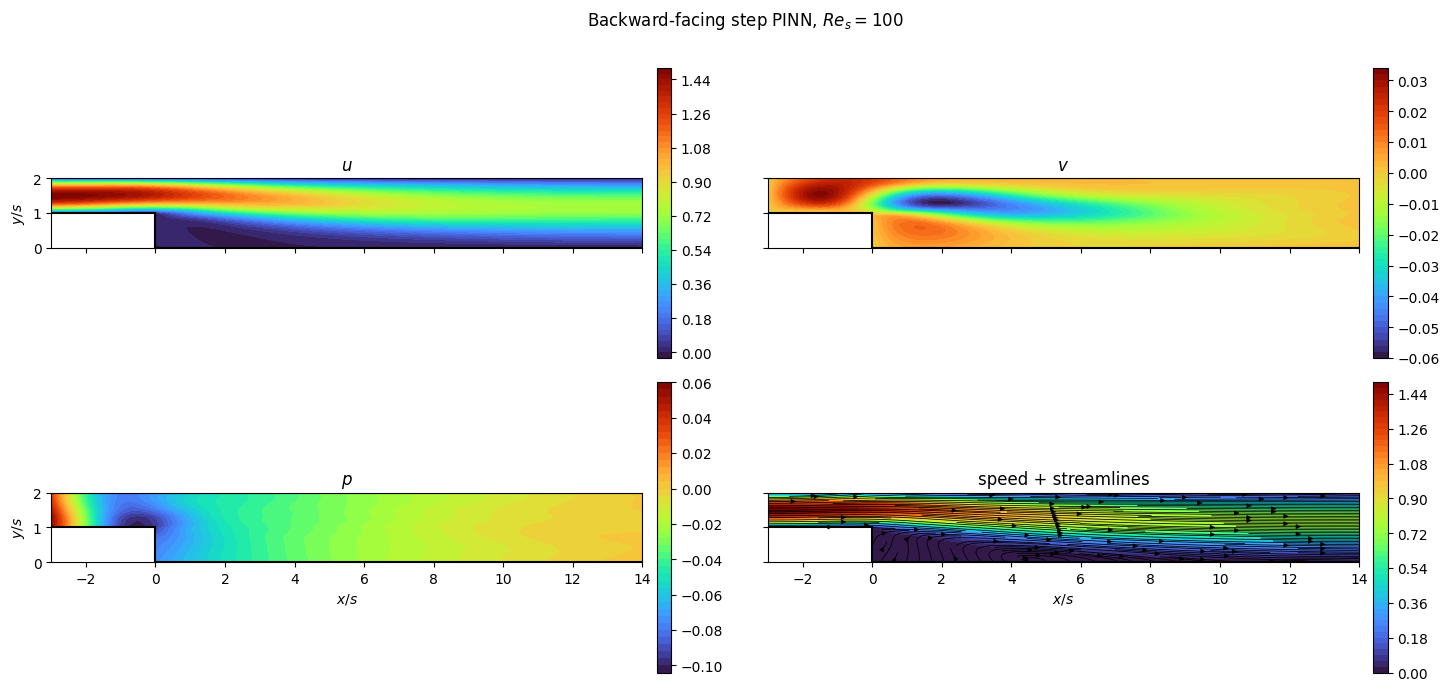

In [12]:
# regular prediction grid
nx,ny = (401,121) if FULL_TRAINING else (181,61)
xg=np.linspace(-Li,Lo,nx); yg=np.linspace(0,H,ny)
X,Y=np.meshgrid(xg,yg)
mask=inside_fluid(X,Y)
pts=np.column_stack([X[mask],Y[mask]])

with torch.no_grad():
    pred=model(torch.tensor(pts,dtype=torch.float32,device=device)).cpu().numpy()

U=np.full_like(X,np.nan,dtype=float); V=np.full_like(X,np.nan,dtype=float); P=np.full_like(X,np.nan,dtype=float)
U[mask]=pred[:,0]; V[mask]=pred[:,1]; P[mask]=pred[:,2]
SPEED=np.sqrt(U**2+V**2)

fig,ax=plt.subplots(2,2,figsize=(15,6.8),sharex=True,sharey=True)
fields_plot=[(U,'$u$'),(V,'$v$'),(P,'$p$'),(SPEED,'speed + streamlines')]
for a,(F,title) in zip(ax.flat,fields_plot):
    c=a.contourf(X,Y,F,levels=50,cmap='turbo')
    plt.colorbar(c,ax=a,pad=0.02)
    a.plot([-Li,Lo],[H,H],color='k',lw=1.5)
    a.plot([-Li,0],[s,s],color='k',lw=1.5)
    a.plot([0,0],[0,s],color='k',lw=1.5)
    a.plot([0,Lo],[0,0],color='k',lw=1.5)
    a.set_title(title); a.set_aspect('equal')

# streamlines on the speed panel
ax[1,1].streamplot(xg,yg,np.ma.masked_invalid(U),np.ma.masked_invalid(V),
                   density=1.6,color='k',linewidth=0.55,arrowsize=0.7)
for a in ax[:,0]: a.set_ylabel('$y/s$')
for a in ax[1,:]: a.set_xlabel('$x/s$')
plt.suptitle(f'Backward-facing step PINN, $Re_s={RE_TARGET:g}$',y=1.01)
plt.tight_layout(); plt.show()

independent residual RMS: rx=2.261e-02, ry=6.818e-03, continuity=1.659e-02
inlet u RMS error:        9.241e-04
maximum wall speed:       3.812e-02
outlet pressure RMS:      1.039e-03
mass flow at x= -3.0: Q=1.00011  error=+1.11e-04
mass flow at x=  1.0: Q=0.86992  error=-1.30e-01
mass flow at x=  4.0: Q=0.89765  error=-1.02e-01
mass flow at x=  8.0: Q=0.86317  error=-1.37e-01
mass flow at x= 11.2: Q=0.83105  error=-1.69e-01
minimum u behind step:    -0.00493
reattachment x_r/s:       3.875


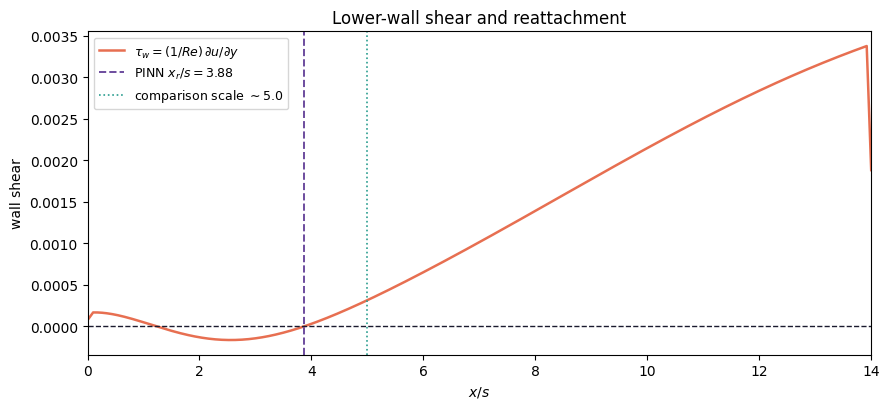

In [13]:
def wall_shear_profile(n=700):
    "Lower-wall shear proportional to du/dy / Re."
    x=torch.linspace(0.02,Lo,n,device=device).reshape(-1,1)
    y=torch.zeros_like(x)
    xy=torch.cat([x,y],dim=1).requires_grad_(True)
    u,_,_=fields(xy)
    u_y=grad(u,xy)[:,1:2]
    return x.detach().cpu().numpy().flatten(),(u_y/RE_TARGET).detach().cpu().numpy().flatten()

def reattachment_length():
    x,tau=wall_shear_profile()
    # light smoothing only for robust sign-change detection
    k=np.ones(9)/9
    tau_s=np.convolve(tau,k,mode='same')
    idx=np.where((x[:-1]>0.5)&(tau_s[:-1]<0)&(tau_s[1:]>=0))[0]
    if len(idx)==0: return np.nan,x,tau_s
    i=idx[0]
    xr=x[i]-tau_s[i]*(x[i+1]-x[i])/(tau_s[i+1]-tau_s[i]+1e-14)
    return xr,x,tau_s

def independent_residual_rms(n=1000):
    xy=sample_interior(n).requires_grad_(True)
    rx,ry,rc=residuals(xy,RE_TARGET)
    return [q.square().mean().sqrt().item() for q in (rx,ry,rc)]

xr,xw,tauw=reattachment_length()
rx_rms,ry_rms,rc_rms=independent_residual_rms(3000 if FULL_TRAINING else 300)

# boundary and mass checks
with torch.no_grad():
    ui,vi,_=fields(xy_in); uw,vw,_=fields(xy_wall); _,_,po=fields(xy_out)
    inlet_err=torch.sqrt(((ui-inlet_velocity(xy_in[:,1:2]))**2).mean()).item()
    wall_speed=torch.sqrt(uw**2+vw**2).max().item()
    outlet_p=torch.sqrt((po**2).mean()).item()

stations=[-Li,1.0,4.0,8.0,0.8*Lo]
flows=[mass_flow(x0) for x0 in stations]
print(f"independent residual RMS: rx={rx_rms:.3e}, ry={ry_rms:.3e}, continuity={rc_rms:.3e}")
print(f"inlet u RMS error:        {inlet_err:.3e}")
print(f"maximum wall speed:       {wall_speed:.3e}")
print(f"outlet pressure RMS:      {outlet_p:.3e}")
for x0,q in zip(stations,flows): print(f"mass flow at x={x0:5.1f}: Q={q:.5f}  error={q-1:+.2e}")
print(f"minimum u behind step:    {minimum_reverse_velocity():+.5f}")
print(f"reattachment x_r/s:       {xr:.3f}" if np.isfinite(xr) else "reattachment not detected")

fig,ax=plt.subplots(figsize=(9,4.2))
ax.plot(xw,tauw,color=CORAL,lw=1.8,label=r'$\tau_w=(1/Re)\,\partial u/\partial y$')
ax.axhline(0,color=INK,lw=1,ls='--')
if np.isfinite(xr):
    ax.axvline(xr,color=PUR,lw=1.4,ls='--',label=fr'PINN $x_r/s={xr:.2f}$')
ax.axvline(XR_REFERENCE,color=TEAL,lw=1.2,ls=':',label=fr'comparison scale $\sim{XR_REFERENCE:.1f}$')
ax.set_xlim(0,Lo); ax.set_xlabel('$x/s$'); ax.set_ylabel('wall shear')
ax.set_title('Lower-wall shear and reattachment')
ax.legend(fontsize=9); plt.tight_layout(); plt.show()

---

## 13 — Exercises

1. **Reynolds-number sweep.** Train at $Re_s=50,75,100,125,150$ and plot $x_r/s$ against $Re_s$. Keep the study in the steady laminar range.
2. **Remove continuation.** Train directly at $Re_s=100$ from the random initialization. Compare loss, minimum $u$, and reattachment length with the continuation result.
3. **Sampling near the corner.** Remove the corner-focused collocation block, then double it. Compare the wall-shear curve and the stability of $x_r$.
4. **Longer outlet.** Change $L_o$ from 14 to 20. Check whether the outlet pressure and zero-gradient condition influence the recirculation bubble.
5. **Expansion ratio.** Change the upstream height while keeping the step height fixed. Rebuild the inlet profile so its mean remains one, then compare bubble size.
6. **Loss weights.** Sweep `W_INLET`, `W_WALL`, and `W_OUTLET`. A low total loss is not enough; use the separate diagnostics to decide which solution is credible.
7. **Reference CFD data.** Import velocity profiles or a reattachment-length table from a laminar finite-volume simulation and add quantitative field comparisons without changing the PINN equations.

---

## 14 — Failure modes to watch for

| Symptom | Cause | Fix |
|---------|-------|-----|
| **Smooth field but no reversed flow** | direct high-Re training, weak wall loss, or too few points near the step | keep the Reynolds continuation; strengthen wall enforcement; add corner and near-wall points |
| **Mass flow changes strongly downstream** | continuity is underweighted relative to boundary terms | inspect the continuity RMS; increase interior points or separate the continuity weight |
| **Large velocities inside the solid notch** | plotting the rectangular bounding box without masking the solid region | apply the L-shaped `inside_fluid` mask before plotting |
| **Outlet controls the whole solution** | outlet too close to reattachment or outlet loss too strong | lengthen $L_o$; reduce `W_OUTLET`; compare profiles before and after the change |
| **Noisy wall-shear crossings** | the velocity field looks smooth but its derivative is less converged | train longer, increase near-wall sampling, and inspect the unsmoothed shear before accepting $x_r$ |
| **Pressure drifts by a constant** | no pressure gauge | keep $p=0$ at the outlet or fix pressure at one point |
| **NaN or out-of-memory during L-BFGS** | full-batch second derivatives and optimizer history are memory intensive | reduce `N_f`, reduce `LBFGS_ITERS`, lower `history_size`, or disable L-BFGS |
| **CUDA available but the run is still slow** | too many collocation points or unnecessary diagnostic calls | first use `FULL_TRAINING=False`; then scale one setting at a time |

---

## 15 — Vocabulary

- **Backward-facing step** — a sudden channel expansion produced by a drop in the wall.
- **Separation** — detachment of the near-wall flow from the solid boundary at the sharp corner.
- **Recirculation bubble** — the downstream region where the local streamwise velocity becomes negative.
- **Reattachment point** — the lower-wall location where the separated shear layer returns to the wall.
- **Reattachment length ($x_r$)** — distance from the step face to the primary reattachment point, usually scaled by step height.
- **Re-entrant corner** — the $270^\circ$ fluid-domain corner at the top of the step face.
- **Expansion ratio ($ER$)** — downstream channel height divided by upstream channel height.
- **Outflow boundary** — an outlet condition intended to let the solution leave without prescribing the full velocity profile.
- **Pressure gauge** — one pressure condition that removes the arbitrary additive constant in incompressible pressure.
- **Wall shear** — the tangential viscous stress at the wall; its sign change identifies reattachment.
- **Reynolds continuation** — training first at lower Reynolds numbers and progressively increasing to the target.
- **Laminar model** — the molecular-viscosity Navier–Stokes equations used directly, with no turbulence closure.

---

## 16 — What You Have Built (and Where the Series Goes)

The notebook now follows the same tutorial structure as the earlier files while solving the actual backward-facing-step problem throughout:

| Choice | What it bought |
|--------|---------------|
| step-height and mean-velocity scaling | every field and coordinate remains near order one |
| L-shaped collocation sampling | physics is enforced only in the fluid, with extra attention near separation |
| direct $(u,v,p)$ network | the formulation stays close to the standard incompressible equations |
| explicit inlet, wall, and outlet losses | every boundary family remains visible and debuggable |
| laminar Reynolds continuation | an easier route from viscous attached flow to a separated target solution |
| wall-shear post-processing | a physical scalar validation target, the reattachment length |

The important result is not a low total loss by itself. A credible solution must simultaneously show small independent residuals, no-slip walls, the correct inlet profile, nearly conserved mass flow, negative $u$ behind the step, and a stable wall-shear sign change.

**The honest engineering verdict:** for a single backward-facing-step geometry, a conventional laminar CFD solver is still the direct and reliable tool. The value of this notebook is that it exposes every part of a PINN solution — geometry sampling, nonlinear residuals, mixed boundaries, training balance, and physics-based validation — in one compact example.

---

### Get the Notebook

The full series — every tutorial, with all plots and training logs — lives on GitHub:

**[github.com/rraj-io/PINN_for_Mechanical_Engineer](https://github.com/rraj-io/PINN_for_Mechanical_Engineer)**

```bash
git clone https://github.com/rraj-io/PINN_for_Mechanical_Engineer.git
cd PINN_for_Mechanical_Engineer
```

New articles and shorter notes on PINNs, neural operators, CFD, and scientific machine learning publish regularly on Substack: **[rajrohit403.substack.com](https://rajrohit403.substack.com/)**

*Next up: unsteady vortex shedding, where time dependence and periodic wake dynamics raise the difficulty again. — Rohit Raj · HalfQubiX*